<div class='bar_title'></div>

*Practical Data Science - Final Project (WS 2026/27)*

# Forecasting German Day-Ahead Electricity Prices
## Part 3: Extension - Predicting Negative-Price Hours

Group members: Rashad Zarbaliyev, [Member 2], [Member 3]<br>
Data: SMARD, Bundesnetzagentur (CC BY 4.0)

### Running this notebook in Google Colab
Run the next cell first. On your own computer it does nothing. In Colab it gets the project files and installs the missing package.
Because the GitHub repository is private, Colab may ask you to upload the project ZIP (`PDS_Submission_Electricity_Price_Forecasting.zip`).

In [ ]:
# Colab setup (skipped automatically when running locally)
import os, sys, subprocess
if 'google.colab' in sys.modules and not os.path.exists('../src/data_pipeline.py'):
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'holidays'])
    repo = 'https://github.com/greenmario2099/pds-electricity-price-forecasting'
    env = dict(os.environ, GIT_TERMINAL_PROMPT='0')
    if not os.path.exists('/content/project'):
        cloned = subprocess.run(['git', 'clone', '-q', '--depth', '1', repo, '/content/project'], env=env).returncode == 0
        if not cloned:
            import glob, zipfile
            from google.colab import files
            print('Repository is private: please upload the project ZIP.')
            name = list(files.upload())[0]
            zipfile.ZipFile(name).extractall('/content/upload')
            pipeline = glob.glob('/content/upload/**/src/data_pipeline.py', recursive=True)[0]
            os.symlink(os.path.dirname(os.path.dirname(pipeline)), '/content/project')
    os.chdir('/content/project/notebooks')
    print('Ready:', os.getcwd())

# Content

* Motivation and problem definition
* Class imbalance
* Models: a simple rule, logistic regression and random forest
* Choosing the decision threshold on the validation year
* Final evaluation on the test set 2026
* Error analysis and interpretation

## Motivation

Negative prices occur when a lot of wind and solar power meets low demand and inflexible power plants keep running.
Producers then **pay** to deliver electricity. Knowing these hours in advance is valuable:

* battery operators can charge for free (and get paid),
* flexible consumers (e.g. electrolysers, heat pumps) can shift consumption,
* operators of renewable plants can curtail production (since 2025, new plants receive no subsidy in negative-price hours).

**Prediction task:** for each hour of day D, predict whether the day-ahead price will be below 0 EUR/MWh,
using only information known at noon on day D-1. This is a **binary classification** problem.

In [1]:
import sys
sys.path.append('..')   # so that we can import our own pipeline from the src/ folder

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from src.data_pipeline import load_data, build_features, FEATURES

import warnings
warnings.filterwarnings('ignore')

%matplotlib inline
plt.rcParams['figure.figsize'] = (12, 4)
DATA_DIR = '../data/'

from src.data_pipeline import split_by_time

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (average_precision_score, f1_score, precision_score, recall_score,
                             precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay)

In [2]:
data = load_data(DATA_DIR)
features = build_features(data)

features['negative'].groupby(features.index.year).agg(['sum', 'mean']).rename(
    columns={'sum': 'negative hours', 'mean': 'share'}).round(3)

,negative hours,share
2018,21,0.014
2019,211,0.024
2020,298,0.034
2021,139,0.016
2022,69,0.008
2023,301,0.034
2024,457,0.052
2025,573,0.065
2026,462,0.060


## Class Imbalance

Only about 5-7% of hours are negative. A model that always predicts "not negative" would reach 94% accuracy and be useless.
We therefore use metrics that focus on the rare class:

* **PR-AUC** (average precision, main metric): area under the precision-recall curve, independent of the threshold.
* **Precision**: of all hours we flag as negative, how many really are?
* **Recall**: of all negative hours, how many do we catch?
* **F1**: harmonic mean of precision and recall at the chosen threshold.

Same split as for the price models. For the test year, the models are retrained on the two years directly before it (2024-2025),
in line with the two-year window used in notebook 02.

In [3]:
train, val, test = split_by_time(features)
test_train = features.loc['2024-01':'2025-12']

for name, df in [('train 2023-24', train), ('validation 2025', val), ('train for test 2024-25', test_train), ('test 2026', test)]:
    print(f'{name:25s} {len(df):6d} hours, {df["negative"].mean():.1%} negative')

train 2023-24              17544 hours, 4.3% negative
validation 2025             8760 hours, 6.5% negative
train for test 2024-25     17544 hours, 5.9% negative
test 2026                   7704 hours, 6.0% negative


## Baseline: A Simple Rule

From the EDA we know that negative prices occur when renewables cover most of the load.
Rule: *predict "negative" if the forecasted renewable share exceeds a threshold.* We choose the threshold with the best F1 on the training data.

In [4]:
thresholds = np.arange(0.5, 1.5, 0.01)
f1_by_threshold = [f1_score(train['negative'], train['renewable_share'] > t) for t in thresholds]
rule_threshold = thresholds[int(np.argmax(f1_by_threshold))]
print('Best renewable share threshold:', round(rule_threshold, 2))

Best renewable share threshold: 0.9


## Models: Logistic Regression and Random Forest

* **Logistic regression** (interpretable, standardized features), as in the lecture
* **Random forest** (can learn non-linear effects)

In [5]:
models = {
    'Logistic regression': lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    'Random forest': lambda: RandomForestClassifier(n_estimators=300, min_samples_leaf=5, max_features=0.5, n_jobs=-1, random_state=1),
}

val_proba = {'Rule: renewable share': val['renewable_share']}
for name, make_model in models.items():
    model = make_model()
    model.fit(train[FEATURES], train['negative'])
    val_proba[name] = model.predict_proba(val[FEATURES])[:, 1]

## Choosing the Decision Threshold (Validation 2025)

Classifiers output a probability. The default cut-off of 0.5 is not necessarily the best, especially with imbalanced classes.
We choose, for each model, the threshold that maximizes F1 on the **validation year** and keep it fixed for the test.

In [6]:
def best_threshold(y_true, score):
    precision, recall, thr = precision_recall_curve(y_true, score)
    f1 = 2 * precision * recall / (precision + recall + 1e-9)
    return thr[np.argmax(f1[:-1])]

def classification_report_row(y_true, score, threshold):
    pred = (np.asarray(score) >= threshold).astype(int)
    return {'PR-AUC': average_precision_score(y_true, score), 'threshold': threshold,
            'precision': precision_score(y_true, pred), 'recall': recall_score(y_true, pred), 'F1': f1_score(y_true, pred)}

chosen_thresholds = {}
val_table = {}
for name, score in val_proba.items():
    chosen_thresholds[name] = rule_threshold if name.startswith('Rule') else best_threshold(val['negative'], score)
    val_table[name] = classification_report_row(val['negative'], score, chosen_thresholds[name])

val_table = pd.DataFrame(val_table).T.sort_values('PR-AUC', ascending=False)
val_table.round(3)

,PR-AUC,threshold,precision,recall,F1
Logistic regression,0.863,0.291,0.718,0.824,0.767
Random forest,0.834,0.407,0.752,0.796,0.774
Rule: renewable share,0.755,0.900,0.694,0.616,0.652


In [7]:
final_classifier = val_table['PR-AUC'].idxmax()
print('Best model on validation (PR-AUC):', final_classifier)

Best model on validation (PR-AUC): Logistic regression


## Final Evaluation on the Test Set (2026)

The models are retrained on 2024-2025 and evaluated once on 2026 with the thresholds chosen on 2025.

In [8]:
test_proba = {'Rule: renewable share': test['renewable_share']}
fitted = {}
for name, make_model in models.items():
    model = make_model()
    model.fit(test_train[FEATURES], test_train['negative'])
    fitted[name] = model
    test_proba[name] = model.predict_proba(test[FEATURES])[:, 1]

test_table = pd.DataFrame({name: classification_report_row(test['negative'], score, chosen_thresholds[name])
                           for name, score in test_proba.items()}).T.sort_values('PR-AUC', ascending=False)
test_table.round(3)

,PR-AUC,threshold,precision,recall,F1
Logistic regression,0.843,0.291,0.619,0.929,0.743
Random forest,0.817,0.407,0.493,0.963,0.652
Rule: renewable share,0.691,0.900,0.462,0.874,0.605


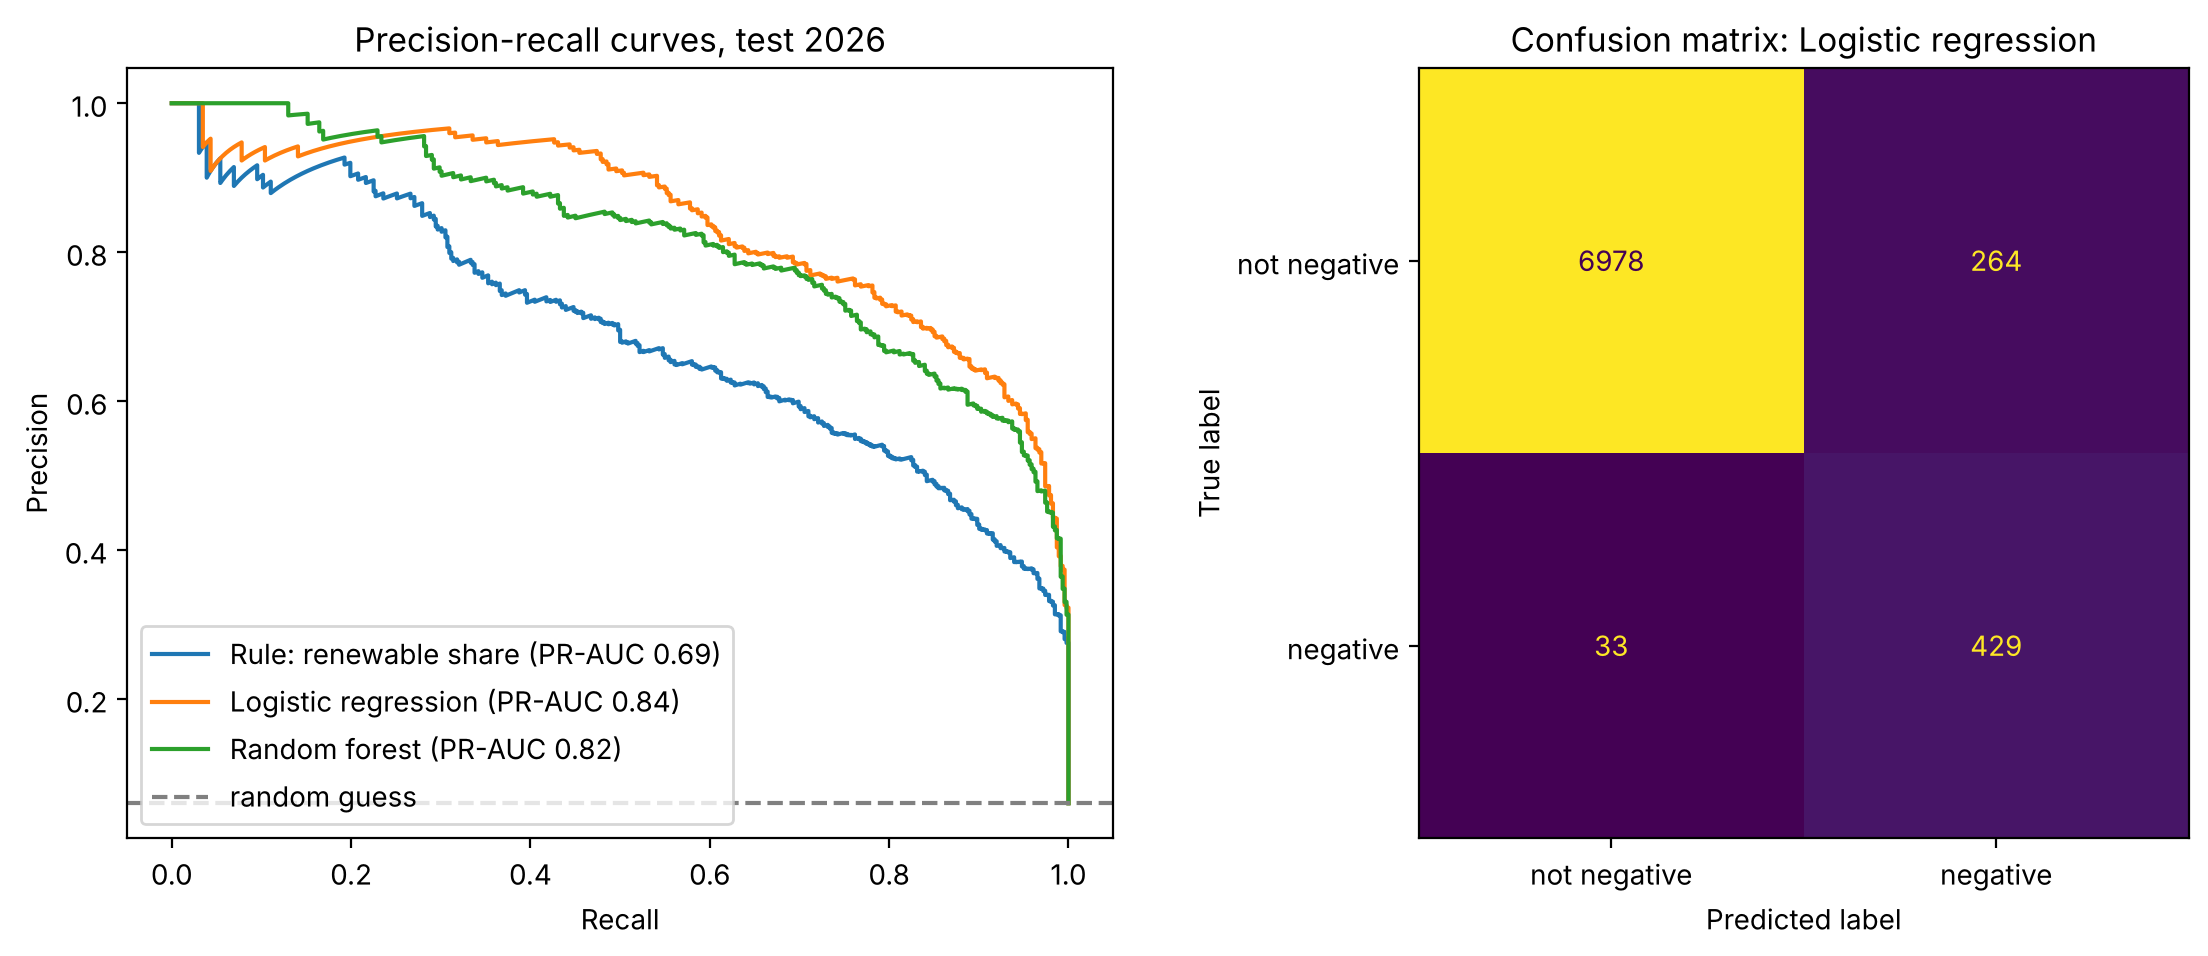

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, score in test_proba.items():
    precision, recall, _ = precision_recall_curve(test['negative'], score)
    axes[0].plot(recall, precision, label=f'{name} (PR-AUC {average_precision_score(test["negative"], score):.2f})')
axes[0].axhline(test['negative'].mean(), color='grey', ls='--', label='random guess')
axes[0].set_xlabel('Recall')
axes[0].set_ylabel('Precision')
axes[0].set_title('Precision-recall curves, test 2026')
axes[0].legend()

final_pred = (test_proba[final_classifier] >= chosen_thresholds[final_classifier]).astype(int)
ConfusionMatrixDisplay(confusion_matrix(test['negative'], final_pred), display_labels=['not negative', 'negative']).plot(ax=axes[1], colorbar=False)
axes[1].set_title(f'Confusion matrix: {final_classifier}');

## Error Analysis

### When does the model miss negative hours, and when does it give false alarms?

In [10]:
result = pd.DataFrame({'actual': test['negative'], 'pred': final_pred, 'price': test['price'],
                       'renewable_share': test['renewable_share']}, index=test.index)
result['type'] = np.select([(result.actual == 1) & (result.pred == 1), (result.actual == 0) & (result.pred == 1),
                            (result.actual == 1) & (result.pred == 0)], ['hit', 'false alarm', 'missed'], 'correct no')

result[result['type'] != 'correct no'].groupby('type').agg(
    hours=('price', 'size'), mean_price=('price', 'mean'), median_price=('price', 'median'),
    mean_renewable_share=('renewable_share', 'mean')).round(2)

,hours,mean_price,median_price,mean_renewable_share
type,,,,
false alarm,264,16.54,5.22,0.98
hit,429,-18.05,-1.88,1.07
missed,33,-0.87,-0.24,0.89


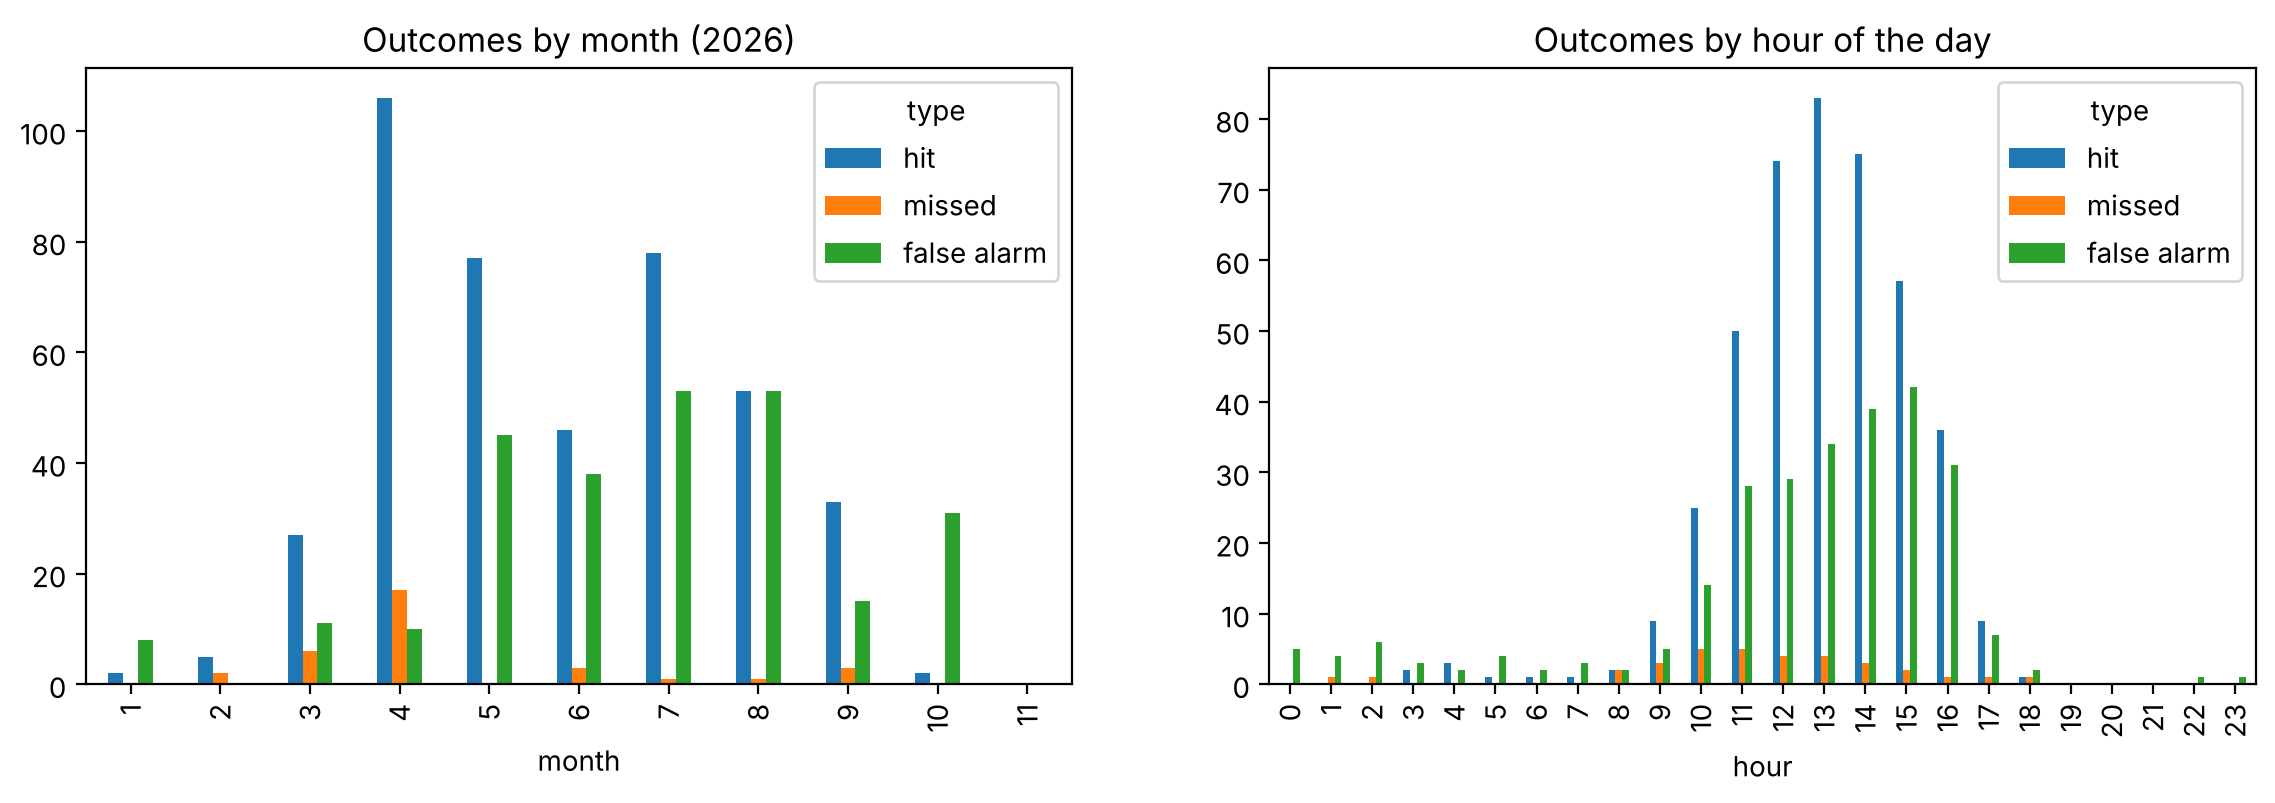

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
pd.crosstab(result.index.month, result['type'], rownames=['month'])[['hit', 'missed', 'false alarm']].plot(kind='bar', ax=axes[0],
                                                                                    title='Outcomes by month (2026)')
pd.crosstab(result.index.hour, result['type'], rownames=['hour'])[['hit', 'missed', 'false alarm']].plot(kind='bar', ax=axes[1],
                                                                                   title='Outcomes by hour of the day');

* Negative hours occur almost only between 9:00 and 17:00 and from March to September: they are driven by solar power.
* **False alarms** (264 hours) have a median price of only about 5 EUR/MWh: the model correctly sees an oversupply situation,
  but the price stays just above zero. For a battery operator such errors are cheap.
* **Missed hours** are rare (33 hours) and have a median price of -0.24 EUR/MWh, so the economic loss is small as well.
* The chosen threshold favours recall (93%) over precision (62%). Depending on the use case, a higher threshold gives fewer false alarms.

### What does the logistic regression use?

The features are standardized, so each coefficient shows how much one standard deviation of a feature changes the log-odds of a negative price.

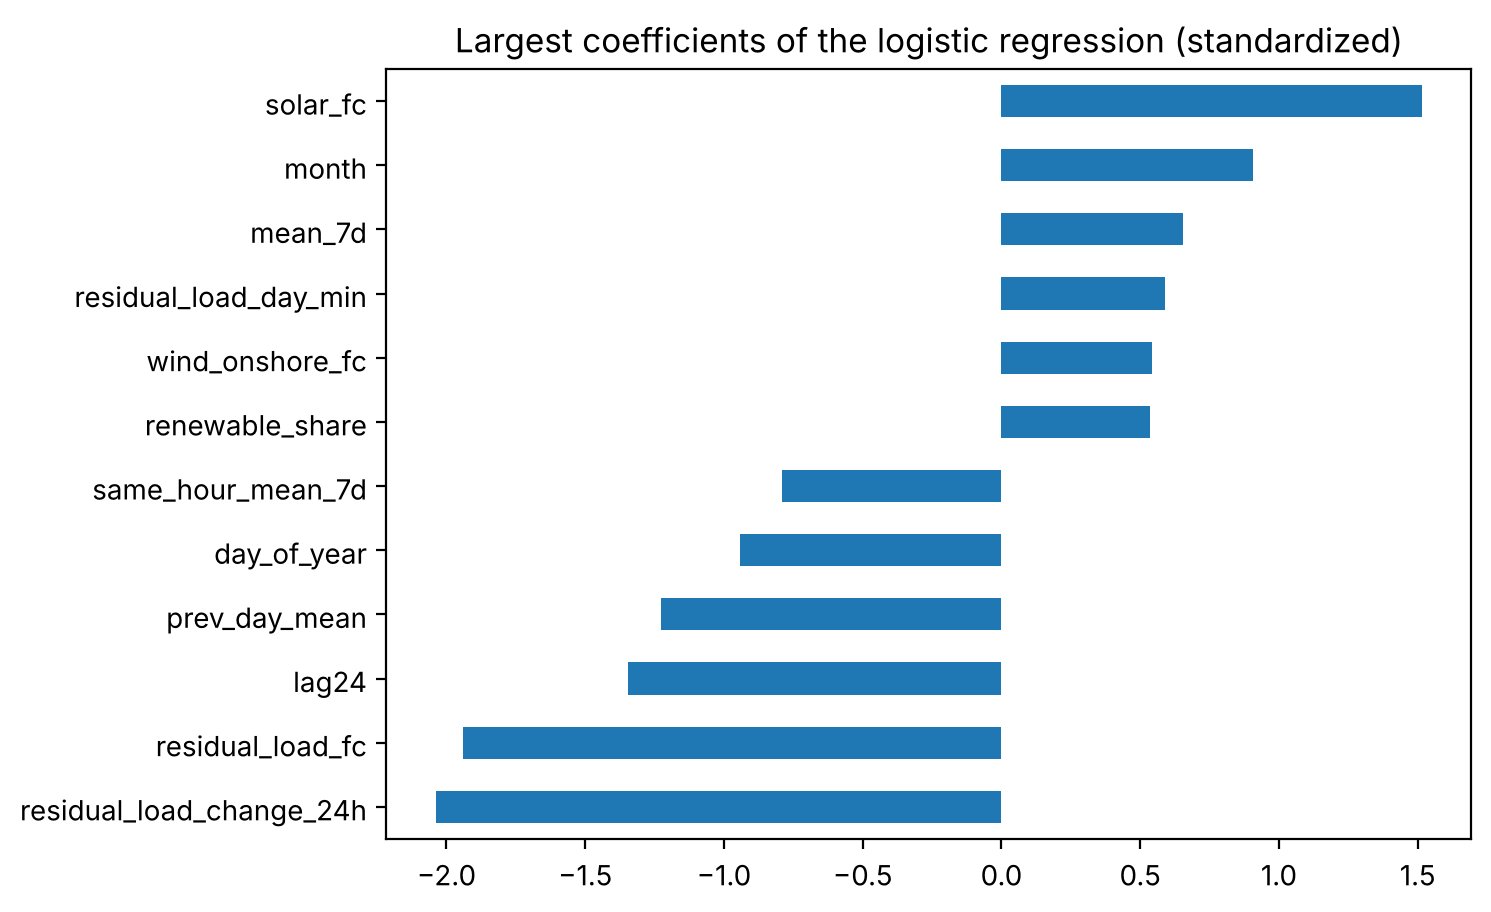

In [12]:
logreg = fitted['Logistic regression']
coefs = pd.Series(logreg[-1].coef_[0], index=FEATURES).sort_values()
pd.concat([coefs.head(6), coefs.tail(6)]).plot(kind='barh', figsize=(7, 5),
                                               title='Largest coefficients of the logistic regression (standardized)');

* A **low residual load** and a **smaller residual load than yesterday** (negative coefficients) strongly increase the probability of negative prices.
* **Low prices on the previous day** (`lag24`, `prev_day_mean`) also increase it: negative-price situations often last several days.
* A **high solar forecast** increases it most among the positive coefficients; together with the effect of `month` and `day_of_year` this
  reflects the spring and summer season.
* Offshore wind has a *negative* coefficient once the other features are known. Offshore wind is high mainly in winter nights,
  when demand is high and solar is zero; this is a correlation within the data, not a causal effect.
  Because many features are correlated, single coefficients should be read with care.

## Summary

* Negative-price hours can be predicted well from SMARD forecasts: all models are far better than random guessing (6% base rate).
* The **logistic regression** had the best PR-AUC on the validation year and also on the test year (0.84; recall 93%, precision 62%).
  The random forest did not improve on it. The key information - low residual load and high solar - separates the classes almost
  linearly, so a simple model is enough. Both learned models clearly beat the simple renewable-share rule (PR-AUC 0.69).
* The thresholds were chosen on the validation year and transferred to the test year without changes.
* Most remaining errors are hours with prices close to zero, where the practical cost of a wrong decision is small.

**Possible extension:** using the predicted probability in a simple battery charging strategy and measuring the revenue.